In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from utils import to_timeseries_input, splitDate, Trainer, PredictReconstruction, PlotResult
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import TensorDataset, DataLoader

### Introduction to Recurrent Neural Networks

In this TP, we will introduce Recurrent Neural Networks (RNNs) and demonstrate how to use them to model time-series data. Specifically, we will be working with the CUBEMS datasets, which contains measurements of temperature, humidity, and light intensity in a 7 floors buildings in Bangkok, Thailand. We will use only a small portion of the data consisting of measurement from 1 zones on the 7th floors. You can explore the dataset by running the cell below.

In [2]:
path = "data.csv"
data = pd.read_csv(path)
data['Date'] = pd.to_datetime(data['Date'])
data = data.set_index('Date')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

For this TP, we will focus on predicting the humidity measurement. We will split the dataset to train and test by taking a date and limit the test data to only 1 months for visualization. 

In [3]:
# Select the columns to use
col = ["humidity"] # 
data = data[[*col]]

date_limit = pd.to_datetime("2019-09-20")
date_limit2 = pd.to_datetime("2019-09-30")
train_date, test_date = splitDate(data.index, date_limit)
train_data = data.loc[data.index < date_limit][col].values
test_data = data.loc[(data.index >= date_limit) & (data.index < date_limit2)][col].values

scaler = MinMaxScaler()
train_data = scaler.fit_transform(train_data)
test_data = scaler.transform(test_data)

We need to convert the data into time-series input. Which is specify by the cell below:

`lookback`: the length of the input sequence

`lookahead`: length of output sequence

`stride`: moving step when split the series (We will keep the default value equal to 1)

To understand how we split, you can look at the function `to_time_series_input` in `utils.py`. 

#### Your job: 
1. Make a train and validation split
2. Convert the data into TensorDataset, you can use the function `torch.from_numpy()``
3. Create DataLoader object for train_dataset, validation dataset and test dataset

In [33]:
# To time series input
lookback = 16
lookahead = 16
batch_size = 32

# Train and validation data
train_input, train_output = to_timeseries_input(train_data, lookback, lookahead)
trainx, validx, trainy, validy = train_test_split(train_input, train_output, test_size=0.2, random_state=42)

train_dataset = TensorDataset(torch.Tensor(trainx), torch.Tensor(trainy))
val_dataset   = TensorDataset(torch.Tensor(validx), torch.Tensor(validy))

# wrap in DataLoaders (Trainer expects DataLoader objects)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# Test data
test_input, test_output = to_timeseries_input(test_data, lookback, lookahead)
test_dataset = TensorDataset(torch.Tensor(test_input), torch.Tensor(test_output))
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Recurrent Neural Network
To build a simple Recurrent Neural Network (RNN) model, we will start with an input layer that takes a sequence of humidity measurements as input. The input tensor has a shape of `(batch_size, T, 1)`, where `batch_size` is the number of sequences in the batch, `T` is the length of each sequence, and `1` is the size of the input vector at each time step.

Next, we will add a hidden layer that is an RNN layer with `hidden_size` units. The hidden layer takes the input sequence and maintains a hidden state vector of size `hidden_size` at each time step. The output of the hidden layer has shape `(batch_size, T, hidden_size)`.

Finally, we will add an output layer that is a fully connected layer with 1 unit. The output layer takes the output vector from the hidden layer and computes the predicted value for `1` timesteps. The output tensor has shape `(batch_size, 1, 1)`.

#### Your job: 
Complete the code below.

In [34]:
hidden_size = 64
in_features = len(col)
out_features =  len(col)
output_length = lookahead
epochs = 10
patience = 5

In [35]:
class SimpleRNN(nn.Module):
    def __init__(self, in_features, hidden_size, out_features):
        """
        Initialize the SimpleRNN model.
        Args:
            in_features (int): The number of input features.
            hidden_size (int): The number of features in the hidden state.
            out_features (int): The number of output features.
        """
        super(SimpleRNN,self).__init__()
        self.rnn = nn.RNN(input_size=in_features, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, out_features)
    def forward(self,x):
        rnn_out, _ = self.rnn(x)
        out = self.fc(rnn_out)
        return out

In [36]:
model =  SimpleRNN(in_features, hidden_size, out_features).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion =  nn.MSELoss()
# Train Loop
trainer = Trainer(model, train_loader, val_loader, test_loader, criterion = criterion, optimizer = optimizer, device = device)

In [37]:
train_loss, train_metric, val_loss, val_metrics = trainer.train(epochs=epochs, patience=patience)

Epoch 0 | Train Loss: 0.0029 | Train MAE: 0.0310 | Val Loss: 0.0021 | Val MAE: 0.0269
Epoch 1 | Train Loss: 0.0021 | Train MAE: 0.0276 | Val Loss: 0.0021 | Val MAE: 0.0259
Epoch 2 | Train Loss: 0.0021 | Train MAE: 0.0273 | Val Loss: 0.0023 | Val MAE: 0.0342
Epoch 3 | Train Loss: 0.0021 | Train MAE: 0.0272 | Val Loss: 0.0021 | Val MAE: 0.0262
Epoch 4 | Train Loss: 0.0021 | Train MAE: 0.0271 | Val Loss: 0.0021 | Val MAE: 0.0262
Epoch 5 | Train Loss: 0.0021 | Train MAE: 0.0270 | Val Loss: 0.0021 | Val MAE: 0.0259
Epoch 6 | Train Loss: 0.0021 | Train MAE: 0.0270 | Val Loss: 0.0021 | Val MAE: 0.0268
Early stopping due to no improvement after 5 epochs


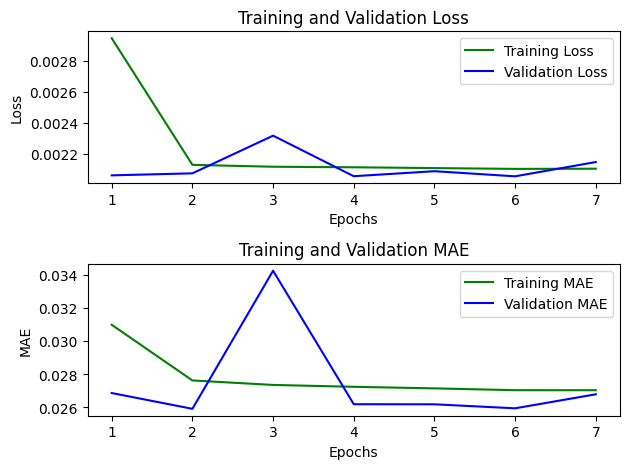

In [38]:
trainer.plot_metrics(train_loss, val_loss, train_metric, val_metrics)

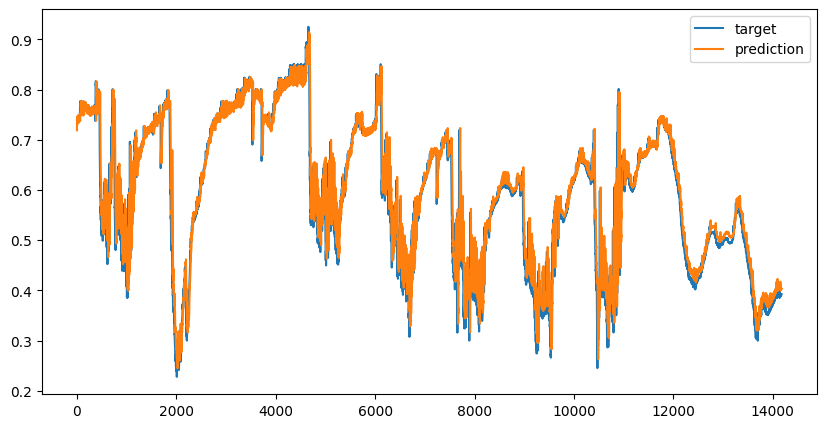

In [40]:
target_rnn, pred_rnn = PredictReconstruction(model, test_loader, lookahead, device)
PlotResult(target_rnn, pred_rnn)

## Exploring Long Short Term Memory (LSTM)

In this section, we are going to explore another type of RNN model, namely Long Short Term Memory (LSTM). Unlike traditional Recurrent Neural Networks (RNNs), which struggle to maintain and utilize information from earlier steps in long sequences due to the vanishing gradient problem, LSTMs are designed to effectively capture long-term dependencies in sequence data.

**Your task**: 

Complete the model definition.

In [41]:
class SimpleLSTM(nn.Module):
    def __init__(self, in_features, hidden_size , out_features):
        #TODO 
        super(SimpleLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=in_features, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, out_features)
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.fc(lstm_out)
        return out

In [42]:
lstm_model =  SimpleLSTM(in_features, hidden_size, out_features).to(device)
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)
criterion = nn.MSELoss()
trainer = Trainer(lstm_model, train_loader, val_loader, test_loader, criterion=criterion, optimizer=optimizer, device=device)

In [43]:
train_loss, train_metric, val_loss, val_metrics = trainer.train(epochs=epochs, patience=patience)

Epoch 0 | Train Loss: 0.0033 | Train MAE: 0.0322 | Val Loss: 0.0021 | Val MAE: 0.0289
Epoch 1 | Train Loss: 0.0021 | Train MAE: 0.0269 | Val Loss: 0.0020 | Val MAE: 0.0270
Epoch 2 | Train Loss: 0.0021 | Train MAE: 0.0267 | Val Loss: 0.0020 | Val MAE: 0.0252
Epoch 3 | Train Loss: 0.0020 | Train MAE: 0.0265 | Val Loss: 0.0020 | Val MAE: 0.0265
Epoch 4 | Train Loss: 0.0020 | Train MAE: 0.0263 | Val Loss: 0.0019 | Val MAE: 0.0251
Epoch 5 | Train Loss: 0.0019 | Train MAE: 0.0258 | Val Loss: 0.0020 | Val MAE: 0.0284
Epoch 6 | Train Loss: 0.0019 | Train MAE: 0.0255 | Val Loss: 0.0018 | Val MAE: 0.0244
Epoch 7 | Train Loss: 0.0019 | Train MAE: 0.0253 | Val Loss: 0.0019 | Val MAE: 0.0250
Epoch 8 | Train Loss: 0.0019 | Train MAE: 0.0252 | Val Loss: 0.0018 | Val MAE: 0.0245
Epoch 9 | Train Loss: 0.0018 | Train MAE: 0.0252 | Val Loss: 0.0018 | Val MAE: 0.0244


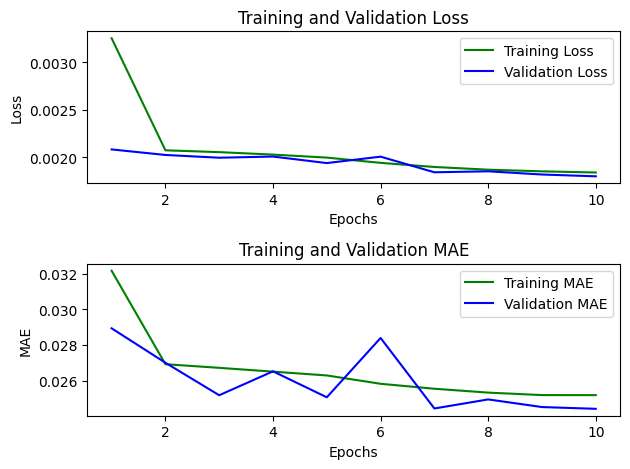

In [44]:
trainer.plot_metrics(train_loss, val_loss, train_metric, val_metrics)

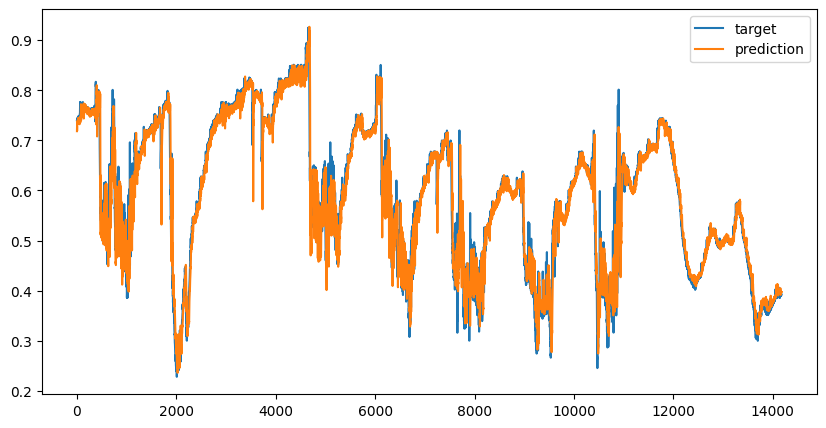

In [46]:
target_lstm, pred_lstm = PredictReconstruction(lstm_model, test_loader, lookahead, device)
PlotResult(target_lstm, pred_lstm)

## Many-to-Many RNN Architecture

The existing code provides a one-step prediction for each time-series. We will now modify this to explore a many-to-many RNN architecture.

Your task is to adapt the existing cells for many-to-many prediction. Here are some suggestions to guide you:

1. **Data Splitting**: Begin by adjusting the data split. Experiment with setting the `lookback` equal to `lookahead`, and then try making `lookback` greater than `lookahead`.

2. **Modify the RNN and LSTM Models**: Adjust the SimpleRNN and Simple LSTM models to accommodate the many-to-many setting.

3. **Training**: Train the model with the new many-to-many setting.

After completing these steps, observe the prediction quality. How does the many-to-many model compare to the original many-to-one model in terms of prediction quality?